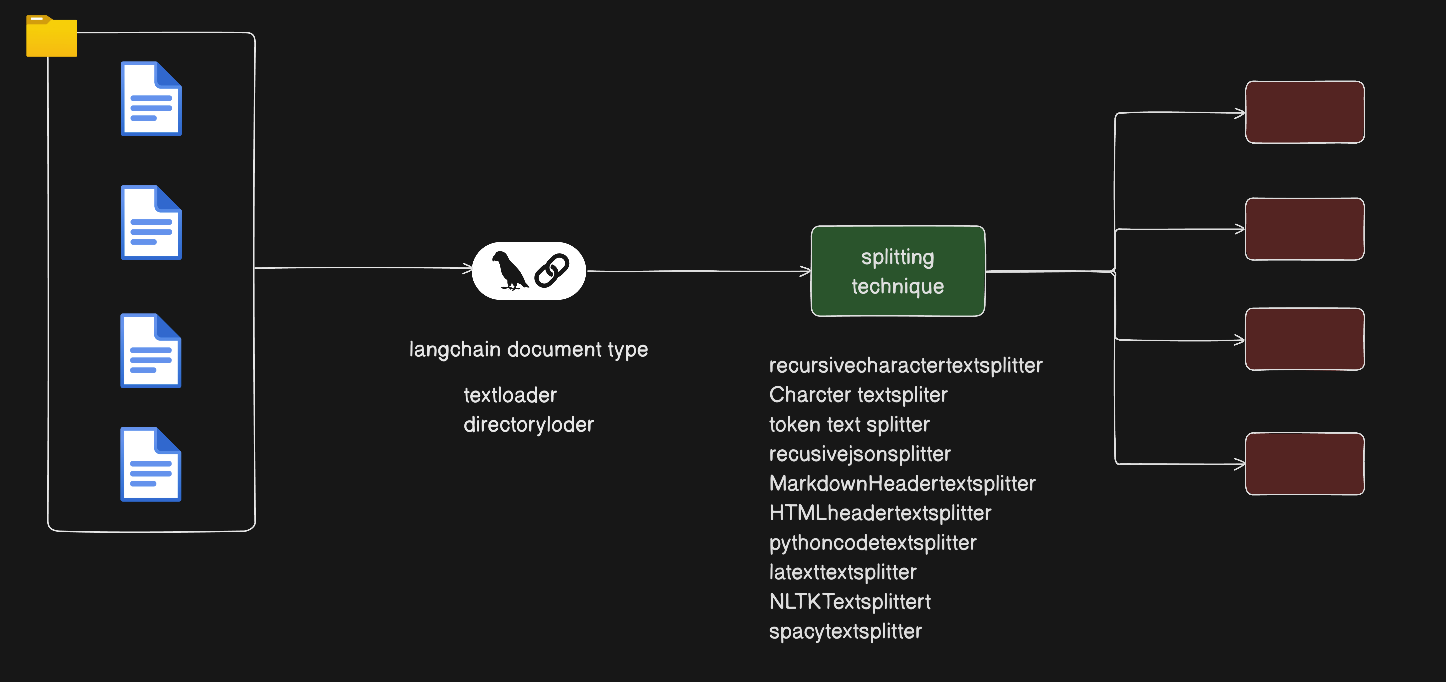

In [3]:
from langchain_community.document_loaders import DirectoryLoader,TextLoader

dir_loader = DirectoryLoader(
    "data/",
    glob="*.txt",
    loader_cls=TextLoader,
    loader_kwargs={'encoding':'utf-8'},
    show_progress=True
)

/var/folders/m8/jv_qd8md6_n84v8zcshwvjm40000gn/T/ipykernel_9512/996648661.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import DirectoryLoader,TextLoader


In [4]:
dir_loader

In [5]:
documents = dir_loader.load()

  0%|          | 0/4 [00:00<?, ?it/s]

100%|██████████| 4/4 [00:00<00:00, 1864.76it/s]


In [6]:
documents[0]

Document(metadata={'source': 'data/machinelearning.txt'}, page_content=' \nMachine Learning (ML) is a core branch of Artificial Intelligence focused on building systems that learn from data.\n\nInstead of relying on hardcoded instructions, ML models extract underlying patterns directly from observations.\n\nThe foundational goal of machine learning is to enable computers to make autonomous decisions without constant human intervention.\n\nIt combines principles from computer science, probability, linear algebra, and mathematical optimization.\n\nThe concept originated in the mid-20th century, notably popularized by pioneer Arthur Samuel in 1959.\n\nToday, modern computing power and massive data availability have accelerated ML into everyday life.\n\nMachine learning is broadly divided into three primary categories: supervised, unsupervised, and reinforcement learning.\n\nSupervised learning trains algorithms on labeled datasets where inputs correspond to known target outputs.\n\nCommon

In [7]:
for i,doc in enumerate(documents):
    print(f"Document {i+1}: ")
    print(f"source: {doc.metadata['source']}")
    print(f"Length: {len(doc.page_content)}")

Document 1: 
source: data/machinelearning.txt
Length: 5925
Document 2: 
source: data/rag.txt
Length: 852
Document 3: 
source: data/python.txt
Length: 816
Document 4: 
source: data/kubernetes.txt
Length: 1432


# Document Splitting

In [8]:
from langchain_text_splitters import CharacterTextSplitter

splitter = CharacterTextSplitter(
    separator="\n",
    chunk_size = 500,
    chunk_overlap = 100,
)

In [9]:
chunks = splitter.split_documents(documents)

In [11]:
len(chunks)

23

In [12]:
chunks[0]

Document(metadata={'source': 'data/machinelearning.txt'}, page_content='Machine Learning (ML) is a core branch of Artificial Intelligence focused on building systems that learn from data.\nInstead of relying on hardcoded instructions, ML models extract underlying patterns directly from observations.\nThe foundational goal of machine learning is to enable computers to make autonomous decisions without constant human intervention.\nIt combines principles from computer science, probability, linear algebra, and mathematical optimization.')

In [13]:
chunks[1]

Document(metadata={'source': 'data/machinelearning.txt'}, page_content='The concept originated in the mid-20th century, notably popularized by pioneer Arthur Samuel in 1959.\nToday, modern computing power and massive data availability have accelerated ML into everyday life.\nMachine learning is broadly divided into three primary categories: supervised, unsupervised, and reinforcement learning.\nSupervised learning trains algorithms on labeled datasets where inputs correspond to known target outputs.')

In [14]:
for i,chunk in enumerate(chunks):
    print(f"===chunk {i+1} ===")
    print(f"pagecontent is : {chunk.page_content}")
    print(f"Metadata: {chunk.metadata}")

===chunk 1 ===
pagecontent is : Machine Learning (ML) is a core branch of Artificial Intelligence focused on building systems that learn from data.
Instead of relying on hardcoded instructions, ML models extract underlying patterns directly from observations.
The foundational goal of machine learning is to enable computers to make autonomous decisions without constant human intervention.
It combines principles from computer science, probability, linear algebra, and mathematical optimization.
Metadata: {'source': 'data/machinelearning.txt'}
===chunk 2 ===
pagecontent is : The concept originated in the mid-20th century, notably popularized by pioneer Arthur Samuel in 1959.
Today, modern computing power and massive data availability have accelerated ML into everyday life.
Machine learning is broadly divided into three primary categories: supervised, unsupervised, and reinforcement learning.
Supervised learning trains algorithms on labeled datasets where inputs correspond to known target o

In [36]:
text = """
Python is a high-level, interpreted programming language celebrated for its clear syntax and exceptional 
readability. Created by Guido van Rossum and released in 1991 
"""

In [40]:
from langchain_text_splitters import CharacterTextSplitter
splitter = CharacterTextSplitter(
    separator="\n",
    chunk_size = 200,
    chunk_overlap = 50
)

In [38]:
len("Python is a high-level, interpreted programming language celebrated")

67

In [19]:
len("for its clear syntax and exceptional readability")

48

In [29]:
len("readability. Created by Guido van Rossum and released in 1991")

61

In [41]:
chunks = splitter.split_text(text)

In [42]:
len(chunks)

1

In [43]:
chunks[0]

'Python is a high-level, interpreted programming language celebrated for its clear syntax and exceptional \nreadability. Created by Guido van Rossum and released in 1991'

In [35]:
chunks[1]

'language celebrated for its clear syntax and exceptional'

In [44]:
New_text = """ 
on is a high-level, interpreted programming language celebrated for its clear syntax and exceptional readability. 
Created by Guido van Rossum and released in 1991. 
its design philosophy emphasizes developer productivity and clean code structure.
"""

In [46]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
splitter = RecursiveCharacterTextSplitter(
    chunk_size = 50,
    chunk_overlap = 0
)

chunk = splitter.split_text(New_text)

In [47]:
chunk

['on is a high-level, interpreted programming',
 'language celebrated for its clear syntax and',
 'exceptional readability.',
 'Created by Guido van Rossum and released in 1991.',
 'its design philosophy emphasizes developer',
 'productivity and clean code structure.']

In [48]:
len(chunk)

6

In [53]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
splitter = RecursiveCharacterTextSplitter(
    chunk_size = 50,
    chunk_overlap = 20
)

chunk = splitter.split_text(New_text)

In [54]:
len(chunk)

8

In [55]:
chunk

['on is a high-level, interpreted programming',
 'programming language celebrated for its clear',
 'for its clear syntax and exceptional readability.',
 'readability.',
 'Created by Guido van Rossum and released in 1991.',
 'released in 1991.',
 'its design philosophy emphasizes developer',
 'developer productivity and clean code structure.']

In [57]:
len("on is a high-level, interpreted programming")

43

In [61]:
from langchain_text_splitters import TokenTextSplitter

New_text = """ 
on is a high-level, interpreted programming language celebrated for its clear syntax and exceptional readability. 
Created by Guido van Rossum and released in 1991. 
its design philosophy emphasizes developer productivity and clean code structure.
"""

splitter = TokenTextSplitter()

chunk = splitter.split_text(New_text)

chunks

['Python is a high-level, interpreted programming language celebrated for its clear syntax and exceptional \nreadability. Created by Guido van Rossum and released in 1991']

In [62]:
len(chunks)

1

## Hello Everyone this is markdown formatter
```
a=10
b=20
print(a+b)
```

```
this is test
```

In [ ]:
from langchain_text_splitters import MarkdownHeaderTextSplitter

markdowntext =""" 

## Hello Everyone this is markdown formatter
```
a=10
b=20
print(a+b)
```

```
this is test
```

"""
headers_to_split_on = [
    ("#", "Header 1"),
    ("##","Header 2")
]



splitter = MarkdownHeaderTextSplitter(
    headers_to_split_on=headers_to_split_on,

)

In [ ]:
chunk = splitter.split_text(markdowntext)

In [66]:
chunk

[Document(metadata={'Header 2': 'Hello Everyone this is markdown formatter'}, page_content='```\na=10\nb=20\nprint(a+b)\n```  \n```\nthis is test\n```')]

In [68]:
from langchain_community.document_loaders import PyPDFLoader

loader = PyPDFLoader("pdfdoc/Learning_Python.pdf")

docs = loader.load()

fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/Subtype': '/Type1', '/FontDescriptor': IndirectObject(12, 0, 4602539632), '/LastChar': 240, '/Widths': [158, 222, 321, 408, 408, 652, 512, 170, 256, 256, 379, 596, 216, 268, 216, 280, 408, 408, 408, 408, 408, 408, 408, 408, 408, 408, 216, 216, 596, 596, 596, 323, 607, 448, 453, 385, 470, 376, 371, 456, 492, 226, 282, 434, 364, 620, 493, 465, 431, 465, 443, 379, 376, 481, 438, 668, 400, 398, 374, 256, 280, 256, 596, 500, 300, 396, 425, 313, 425, 394, 260, 425, 434, 205, 208, 386, 205, 653, 434, 410, 425, 425, 273, 308, 286, 428, 374, 594, 370, 370, 334, 256, 210, 256, 596, 158, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 408, 408, 0, 274, 0, 0, 0, 677, 0, 0, 0, 158, 0, 0, 158, 596, 158, 158, 0, 428, 158, 158, 158, 158, 158, 0, 0, 158, 0, 0, 0, 0, 0, 158, 0, 158, 158, 0, 0, 0, 158, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 158, 0, 0, 0, 0, 0, 0, 

In [69]:
docs[0]

Document(metadata={'producer': 'Antenna House PDF Output Library 2.6.0 (Linux)', 'creator': 'XSL Formatter V4.3 R1 (4,3,2008,0424) for Linux', 'creationdate': '2009-09-14T12:13:26-05:00', 'author': 'Mark Lutz', 'moddate': '2009-09-24T12:55:28-07:00', 'title': 'Learning Python', 'trapped': '/False', 'source': 'pdfdoc/Learning_Python.pdf', 'total_pages': 1213, 'page': 0, 'page_label': '1'}, page_content='')

In [70]:
docs[0].metadata

{'producer': 'Antenna House PDF Output Library 2.6.0 (Linux)',
 'creator': 'XSL Formatter V4.3 R1 (4,3,2008,0424) for Linux',
 'creationdate': '2009-09-14T12:13:26-05:00',
 'author': 'Mark Lutz',
 'moddate': '2009-09-24T12:55:28-07:00',
 'title': 'Learning Python',
 'trapped': '/False',
 'source': 'pdfdoc/Learning_Python.pdf',
 'total_pages': 1213,
 'page': 0,
 'page_label': '1'}

In [77]:
print(docs[4].page_content[:100])

Learning Python, Fourth Edition
by Mark Lutz
Copyright © 2009 Mark Lutz. All rights reserved.
Printe


In [78]:
print(docs[4].metadata)

{'producer': 'Antenna House PDF Output Library 2.6.0 (Linux)', 'creator': 'XSL Formatter V4.3 R1 (4,3,2008,0424) for Linux', 'creationdate': '2009-09-14T12:13:26-05:00', 'author': 'Mark Lutz', 'moddate': '2009-09-24T12:55:28-07:00', 'title': 'Learning Python', 'trapped': '/False', 'source': 'pdfdoc/Learning_Python.pdf', 'total_pages': 1213, 'page': 4, 'page_label': '5'}


In [79]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter(
    chunk_size = 1000,
    chunk_overlap = 200
)

chunks = splitter.split_documents(docs)

In [80]:
len(chunks)

3572

In [83]:
chunks[0]

Document(metadata={'producer': 'Antenna House PDF Output Library 2.6.0 (Linux)', 'creator': 'XSL Formatter V4.3 R1 (4,3,2008,0424) for Linux', 'creationdate': '2009-09-14T12:13:26-05:00', 'author': 'Mark Lutz', 'moddate': '2009-09-24T12:55:28-07:00', 'title': 'Learning Python', 'trapped': '/False', 'source': 'pdfdoc/Learning_Python.pdf', 'total_pages': 1213, 'page': 1, 'page_label': '2'}, page_content='Learning Python')

In [84]:
chunks[1]

Document(metadata={'producer': 'Antenna House PDF Output Library 2.6.0 (Linux)', 'creator': 'XSL Formatter V4.3 R1 (4,3,2008,0424) for Linux', 'creationdate': '2009-09-14T12:13:26-05:00', 'author': 'Mark Lutz', 'moddate': '2009-09-24T12:55:28-07:00', 'title': 'Learning Python', 'trapped': '/False', 'source': 'pdfdoc/Learning_Python.pdf', 'total_pages': 1213, 'page': 3, 'page_label': '4'}, page_content='FOURTH EDITION\nLearning Python\nMark Lutz\nBeijing • Cambridge • Farnham • Köln • Sebastopol • Taipei • Tokyo')